# Regression 2.2: Predict the number of goals scored by a team in a 2026 World Cup match using only information that is available before the match

# Importing libraries

In [1]:
import pandas as pd
import numpy as np
import math
import os
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PowerTransformer

# folder for saving the figures used in the report
os.makedirs("figures", exist_ok=True)

# Loading the data

We are using four datasets:
Match by match results of the 2026 World Cup: https://fbref.com/en/comps/1/schedule/World-Cup-Scores-and-Fixtures
FIFA ranking before the World Cup: https://inside.fifa.com/fifa-rankings/world-ranking/men?dateId=FRS_Male_Football_20260401
International results from 2022 to 2026: https://github.com/martj42/international_results
World Cup finals matches from 1930 to 2022

In [2]:
# Reading the world cup 2026 matches csv
df_matches = pd.read_csv("worldcup_matches_data.csv")

# Reading the FIFA ranking (10 June 2026)
df_rank = pd.read_csv("fifa_ranking_june2026.csv")

# Reading the international results from 2022 to 2026
df_results = pd.read_csv("international_results_2022_2026.csv")

# Reading the World Cup finals matches from 1930 to 2022
df_wc_history = pd.read_csv("world_cup_history.csv")

print("World Cup 2026 matches: %d rows" % df_matches.shape[0])
print("FIFA ranking: %d teams" % df_rank.shape[0])
print("International results 2022-2026: %d matches" % df_results.shape[0])
print("World Cup history 1930-2022: %d matches" % df_wc_history.shape[0])

World Cup 2026 matches: 107 rows
FIFA ranking: 48 teams
International results 2022-2026: 3648 matches
World Cup history 1930-2022: 964 matches


# Data wrangling

The csv has blank rows that we don't need and the Score column is a text value like 2–1, so we split it into home goals and away goals. Penalty shootout scores in brackets are removed because they are not goals scored during the match.
The team names also have country codes attached (e.g. "Mexico mx" and "za South Africa") and some teams are named differently in the other datasets (e.g. "Korea Republic" and "South Korea"), so we clean the names.

In [3]:
# dropping the empty rows
df_matches = df_matches.dropna(subset=["Score"])
df_matches = df_matches[df_matches["Score"].str.strip() != ""]
df_matches = df_matches.reset_index(drop=True)

# removing the penalty shootout scores
df_matches["Score_clean"] = df_matches["Score"].str.replace(r"\(.*?\)", "", regex=True)
df_matches["Score_clean"] = df_matches["Score_clean"].str.strip()

# splitting the goals into Home_Goals and Away_Goals
df_matches[["Home_Goals", "Away_Goals"]] = df_matches["Score_clean"].str.split("–", expand=True)

# converting the goal columns from text to whole numbers
df_matches["Home_Goals"] = df_matches["Home_Goals"].astype(int)
df_matches["Away_Goals"] = df_matches["Away_Goals"].astype(int)

# removing the country codes (end of the home team name, start of the away team name)
df_matches["Home"] = df_matches["Home"].str.rsplit(" ", n=1).str[0]
df_matches["Away"] = df_matches["Away"].str.split(" ", n=1).str[1]

# renaming the teams so the names are the same in all datasets
name_changes = {
    "Korea Republic": "South Korea",
    "Czechia": "Czech Republic",
    "Bosnia–Herz": "Bosnia and Herzegovina",
    "USA": "United States",
    "Côte d'Ivoire": "Ivory Coast",
    "Cabo Verde": "Cape Verde",
    "Congo DR": "DR Congo",
    "IR Iran": "Iran",
    "Türkiye": "Turkey"
}
df_matches["Home"] = df_matches["Home"].replace(name_changes)
df_matches["Away"] = df_matches["Away"].replace(name_changes)

# converting the date column to a date
df_matches["Date"] = pd.to_datetime(df_matches["Date"], format="%m/%d/%Y")

# giving each match an ID number
df_matches["Match_ID"] = range(1, len(df_matches) + 1)

# 1 for knockout matches, 0 for group stage matches
df_matches["Knockout"] = np.where(df_matches["Round"] == "Group stage", 0, 1)

print("Matches remaining after cleaning: %d" % df_matches.shape[0])

# checking that every team can be found in the ranking file
all_teams = set(df_matches["Home"]) | set(df_matches["Away"])
print("Teams not found in the ranking file:", all_teams - set(df_rank["Team"]))

# Displaying the top 10 rows
df_matches[["Match_ID", "Round", "Home", "Home_Goals", "Away_Goals", "Away", "Knockout"]].head(10)

Matches remaining after cleaning: 104
Teams not found in the ranking file: set()


,Match_ID,Round,Home,Home_Goals,Away_Goals,Away,Knockout
0,1,Group stage,Mexico,2,0,South Africa,0
1,2,Group stage,South Korea,2,1,Czech Republic,0
2,3,Group stage,Canada,1,1,Bosnia and Herzegovina,0
3,4,Group stage,United States,4,1,Paraguay,0
4,5,Group stage,Qatar,1,1,Switzerland,0
5,6,Group stage,Brazil,1,1,Morocco,0
6,7,Group stage,Australia,2,0,Turkey,0
7,8,Group stage,Haiti,0,1,Scotland,0
8,9,Group stage,Germany,7,1,Curaçao,0
9,10,Group stage,Netherlands,2,2,Japan,0


# Team information before the World Cup

For each team we are calculating the average goals scored and average goals conceded per match in the last World Cup cycle December 2022 to 2026, and the number of previous World Cups.

In [4]:
# converting the date column to a date
df_results["date"] = pd.to_datetime(df_results["date"])

# keeping only the matches between the 2022 World Cup final and the 2026 World Cup
df_cycle = df_results[(df_results["date"] > "2022-12-18") & (df_results["date"] < "2026-06-11")]
print("Matches in the 2022-2026 cycle: %d" % df_cycle.shape[0])

# putting the home side and the away side of each match underneath each other
home_side = df_cycle[["home_team", "home_score", "away_score"]].rename(
    columns={"home_team": "Team", "home_score": "Goals_For", "away_score": "Goals_Against"})
away_side = df_cycle[["away_team", "away_score", "home_score"]].rename(
    columns={"away_team": "Team", "away_score": "Goals_For", "home_score": "Goals_Against"})
df_team_games = pd.concat([home_side, away_side], ignore_index=True)

# calculating the average goals for each team
df_form = df_team_games.groupby("Team").agg(
    Pre_Matches=("Goals_For", "count"),
    Pre_GoalsFor=("Goals_For", "mean"),
    Pre_GoalsAgainst=("Goals_Against", "mean")
).reset_index()

# counting the number of previous World Cups for each team
df_wc_history["Year"] = pd.to_datetime(df_wc_history["date"]).dt.year
wc_home = df_wc_history[["home_team", "Year"]].rename(columns={"home_team": "Team"})
wc_away = df_wc_history[["away_team", "Year"]].rename(columns={"away_team": "Team"})
df_wc_teams = pd.concat([wc_home, wc_away]).drop_duplicates()
df_apps = df_wc_teams.groupby("Team").size().reset_index(name="WC_Apps")

Matches in the 2022-2026 cycle: 3648


In [5]:
# joining the team information into one table
df_teams = pd.merge(df_rank, df_form, on="Team", how="left")
df_teams = pd.merge(df_teams, df_apps, on="Team", how="left")

print("Missing values:")
print(df_teams.isnull().sum())

# Cape Verde, Curaçao, Jordan and Uzbekistan are playing their first World Cup, so their WC_Apps is 0
print("\nTeams with no previous World Cup:", list(df_teams[df_teams["WC_Apps"].isnull()]["Team"]))
df_teams["WC_Apps"] = df_teams["WC_Apps"].fillna(0).astype(int)

# 1 for the three host nations, 0 for everyone else
hosts = ["United States", "Mexico", "Canada"]
df_teams["Host"] = np.where(df_teams["Team"].isin(hosts), 1, 0)

# Displaying the team table
df_teams.sort_values("FIFA_Rank").round(2)

Missing values:
Team                0
FIFA_Rank           0
Pre_Matches         0
Pre_GoalsFor        0
Pre_GoalsAgainst    0
WC_Apps             4
dtype: int64

Teams with no previous World Cup: ['Uzbekistan', 'Jordan', 'Cape Verde', 'Curaçao']


,Team,FIFA_Rank,Pre_Matches,Pre_GoalsFor,Pre_GoalsAgainst,WC_Apps,Host
0,Argentina,1,39,2.18,0.36,18,0
1,Spain,2,41,2.63,0.83,16,0
2,France,3,40,2.22,0.88,16,0
3,England,4,41,2.10,0.56,16,0
4,Portugal,5,40,2.55,0.82,8,0
5,Brazil,6,37,1.78,1.14,22,0
6,Morocco,7,51,2.16,0.37,6,0
7,Netherlands,8,40,2.35,1.08,11,0
8,Belgium,9,38,2.29,0.84,14,0
9,Germany,10,40,2.15,1.20,20,0


# Team form during the tournament

We are turning the 104 matches into 208 rows (one row for each team in each match). For each row we only use the team's earlier matches in the tournament, so nothing from the match itself is used.

In [6]:
# one row for the home team and one row for the away team of each match
home_rows = df_matches[["Match_ID", "Date", "Knockout", "Home", "Away", "Home_Goals", "Away_Goals"]].rename(
    columns={"Home": "Team", "Away": "Opponent", "Home_Goals": "Goals", "Away_Goals": "Conceded"})
home_rows["Side"] = "Home"
away_rows = df_matches[["Match_ID", "Date", "Knockout", "Away", "Home", "Away_Goals", "Home_Goals"]].rename(
    columns={"Away": "Team", "Home": "Opponent", "Away_Goals": "Goals", "Home_Goals": "Conceded"})
away_rows["Side"] = "Away"
df_long = pd.concat([home_rows, away_rows], ignore_index=True)

# sorting each team's matches by date
df_long = df_long.sort_values(["Team", "Date"]).reset_index(drop=True)

# number of matches the team played before this one
df_long["Prev_Matches"] = df_long.groupby("Team").cumcount()

# goals before this match (running total minus the current match)
df_long["Prev_Goals"] = df_long.groupby("Team")["Goals"].cumsum() - df_long["Goals"]

# average goals scored per match before this match
df_long["Tourn_GoalsFor"] = df_long["Prev_Goals"] / df_long["Prev_Matches"]

print("Rows: %d" % df_long.shape[0])

# Displaying Argentina's matches as an example
df_long[df_long["Team"] == "Argentina"][["Match_ID", "Date", "Opponent", "Goals", "Conceded", "Prev_Matches", "Tourn_GoalsFor"]]

Rows: 208


,Match_ID,Date,Opponent,Goals,Conceded,Prev_Matches,Tourn_GoalsFor
4,19,2026-06-16,Algeria,3,0,0,NaN
5,41,2026-06-22,Austria,2,0,1,3.000000
6,71,2026-06-27,Jordan,3,1,2,2.500000
7,87,2026-07-03,Cape Verde,3,2,3,2.666667
8,95,2026-07-07,Egypt,3,2,4,2.750000
9,100,2026-07-11,Switzerland,3,1,5,2.800000
10,102,2026-07-15,England,2,1,6,2.833333
11,104,2026-07-19,Spain,0,1,7,2.714286


# Handling missing values

A team's first match has no earlier matches in the tournament, so Tourn_GoalsFor is missing. We replace it with the team's average goals per match before the World Cup, which is the best estimate we have before its first match.

In [7]:
print("Missing values:")
print(df_long[["Tourn_GoalsFor"]].isnull().sum())

# adding the team information to each row
df_long = pd.merge(df_long, df_teams, on="Team", how="left")

# replacing the missing values with the team's average goals before the World Cup
df_long["Tourn_GoalsFor"] = df_long["Tourn_GoalsFor"].fillna(df_long["Pre_GoalsFor"])

Missing values:
Tourn_GoalsFor    48
dtype: int64


# Data preparation

The 8 explanatory variables are:
* Team_Rank – FIFA ranking of the team
* Opp_Rank – FIFA ranking of the opponent
* Team_GoalsFor_Pre – team's goals scored per match before the World Cup
* Opp_GoalsAgainst_Pre – opponent's goals conceded per match before the World Cup
* Team_WC_Apps – team's number of previous World Cups
* Host – 1 if the team is a host nation
* Knockout – 1 if it is a knockout match
* Team_Tourn_GoalsFor – team's goals scored per match in earlier 2026 World Cup matches

In [8]:
# adding the opponent's ranking and goals conceded before the World Cup
df_opp = df_teams[["Team", "FIFA_Rank", "Pre_GoalsAgainst"]].rename(
    columns={"Team": "Opponent", "FIFA_Rank": "Opp_Rank", "Pre_GoalsAgainst": "Opp_GoalsAgainst_Pre"})
df_22 = pd.merge(df_long, df_opp, on="Opponent", how="left")

# renaming the team columns
df_22 = df_22.rename(columns={"FIFA_Rank": "Team_Rank",
                              "Pre_GoalsFor": "Team_GoalsFor_Pre",
                              "WC_Apps": "Team_WC_Apps",
                              "Tourn_GoalsFor": "Team_Tourn_GoalsFor"})

# sorting by match (home team first)
df_22 = df_22.sort_values(["Match_ID", "Side"], ascending=[True, False]).reset_index(drop=True)

# keeping the ID fields, the 8 explanatory variables and the response variable (last column)
df_22 = df_22[["Match_ID", "Team", "Opponent",
               "Team_Rank", "Opp_Rank", "Team_GoalsFor_Pre", "Opp_GoalsAgainst_Pre",
               "Team_WC_Apps", "Host", "Knockout", "Team_Tourn_GoalsFor",
               "Goals"]]

print("Dataset: %d rows and %d columns" % (df_22.shape[0], df_22.shape[1]))
print("Missing values: %d" % df_22.isnull().sum().sum())

# saving the dataset
df_22.round(4).to_csv("regression_2_2_dataset.csv", index=False)

# Displaying the top 10 rows
df_22.head(10).round(2)

Dataset: 208 rows and 12 columns
Missing values: 0


,Match_ID,Team,Opponent,Team_Rank,Opp_Rank,Team_GoalsFor_Pre,Opp_GoalsAgainst_Pre,Team_WC_Apps,Host,Knockout,Team_Tourn_GoalsFor,Goals
0,1,Mexico,South Africa,14,60,1.54,0.84,17,1,0,1.54,2
1,1,South Africa,Mexico,60,14,1.43,0.93,3,0,0,1.43,0
2,2,South Korea,Czech Republic,25,40,2.00,1.08,11,0,0,2.00,2
3,2,Czech Republic,South Korea,40,25,1.97,0.88,1,0,0,1.97,1
4,3,Canada,Bosnia and Herzegovina,30,64,1.44,1.70,2,1,0,1.44,1
5,3,Bosnia and Herzegovina,Canada,64,30,1.18,0.95,1,0,0,1.18,1
6,4,United States,Paraguay,17,41,1.94,1.00,11,1,0,1.94,4
7,4,Paraguay,United States,41,17,1.00,1.19,8,0,0,1.00,1
8,5,Qatar,Switzerland,56,19,1.45,1.08,1,0,0,1.45,1
9,5,Switzerland,Qatar,19,56,1.95,1.47,12,0,0,1.95,1


# Loading the dataset for the regression

In [9]:
# Reading the dataset we just saved
df = pd.read_csv("regression_2_2_dataset.csv")

# Removing the ID fields because they are not used for predictions
df = df.drop(["Match_ID", "Team", "Opponent"], axis=1)

df.describe().round(2)

,Team_Rank,Opp_Rank,Team_GoalsFor_Pre,Opp_GoalsAgainst_Pre,Team_WC_Apps,Host,Knockout,Team_Tourn_GoalsFor,Goals
count,208.00,208.00,208.00,208.00,208.00,208.00,208.00,208.00,208.00
mean,27.76,27.76,1.89,0.92,8.03,0.07,0.31,1.75,1.48
std,22.95,22.95,0.45,0.29,6.27,0.26,0.46,0.99,1.39
min,1.00,1.00,1.00,0.36,0.00,0.00,0.00,0.00,0.00
25%,8.75,8.75,1.54,0.74,3.00,0.00,0.00,1.00,0.00
50%,22.50,22.50,1.94,0.88,6.00,0.00,0.00,1.81,1.00
75%,41.00,41.00,2.22,1.08,14.00,0.00,1.00,2.25,2.00
max,85.00,85.00,2.92,1.70,22.00,1.00,1.00,7.00,7.00


# Exploring the data

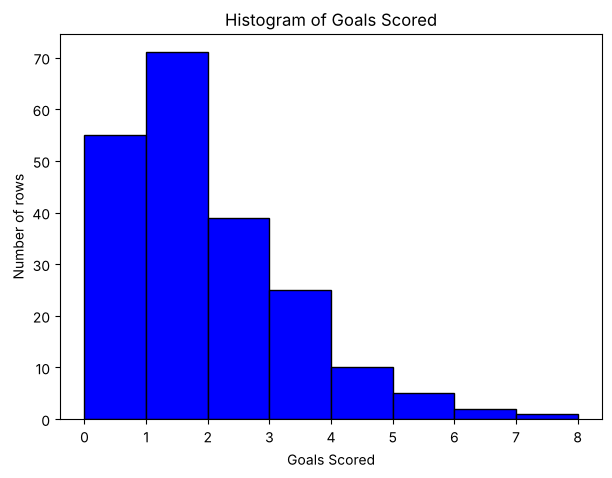

In [10]:
# Plotting a histogram of goals scored
plt.figure(figsize=(7,5))
plt.hist(df["Goals"], bins=range(0, 9), edgecolor="black", color="blue")
plt.xlabel("Goals Scored")
plt.ylabel("Number of rows")
plt.title("Histogram of Goals Scored")
plt.show()

In [11]:
# Checking for outliers using the IQR method
pct25 = np.percentile(df["Goals"], 25)
pct75 = np.percentile(df["Goals"], 75)
iqr = pct75 - pct25
lower = pct25 - 1.5 * iqr
upper = pct75 + 1.5 * iqr
outliers = df[(df["Goals"] < lower) | (df["Goals"] > upper)]

print("IQR: %.2f (25th percentile: %.2f, 75th percentile: %.2f)" % (iqr, pct25, pct75))
print("Outlier boundaries: below %.2f or above %.2f" % (lower, upper))
print("Number of outliers: %d" % len(outliers))
print("Outlier values:", list(outliers["Goals"]))

# outliers are real match results, so all rows are kept

IQR: 2.00 (25th percentile: 0.00, 75th percentile: 2.00)
Outlier boundaries: below -3.00 or above 5.00
Number of outliers: 3
Outlier values: [7, 6, 6]


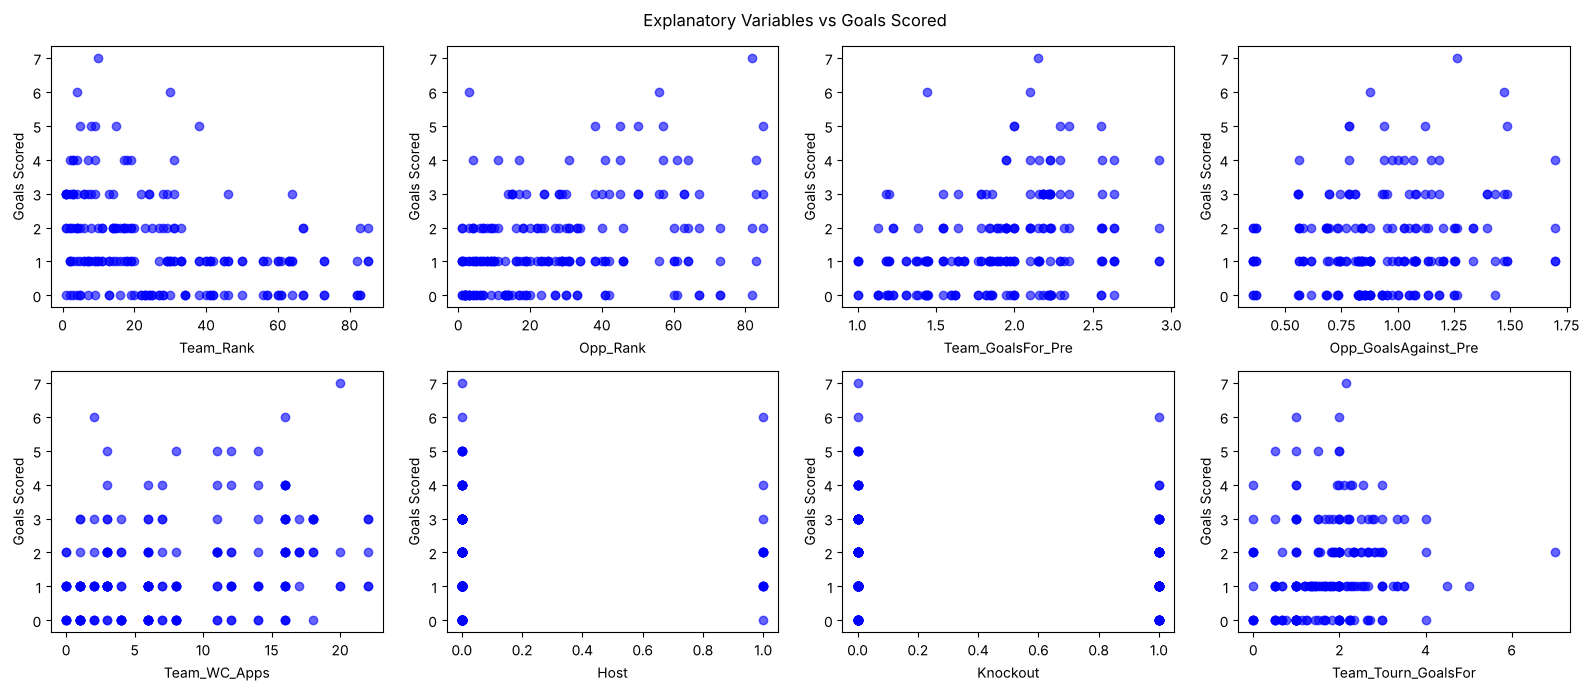

Correlation with Goals:
Team_Rank              -0.37
Opp_Rank                0.35
Team_GoalsFor_Pre       0.32
Opp_GoalsAgainst_Pre    0.17
Team_WC_Apps            0.34
Host                    0.10
Knockout               -0.01
Team_Tourn_GoalsFor     0.13
Name: Goals, dtype: float64


In [12]:
# Plotting each explanatory variable against Goals to check linearity
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(16,7))
for ax, col in zip(axes.flatten(), df.columns[:-1]):
    ax.scatter(df[col], df["Goals"], color="blue", alpha=0.6)
    ax.set_xlabel(col)
    ax.set_ylabel("Goals Scored")
fig.suptitle("Explanatory Variables vs Goals Scored")
fig.tight_layout()
plt.savefig("figures/2_2_scatterplots.png", dpi=150, bbox_inches="tight")
plt.show()

# Calculating the correlation of each variable with Goals
print("Correlation with Goals:")
print(df.corr()["Goals"].drop("Goals").round(2))

# Building the linear regression model

Same as the practicals, we split the data into 60% training and 40% test sets.

In [13]:
# Separate explanatory variables (x) from the response variable (y)
x = df.iloc[:,:-1].values
y = df.iloc[:,-1].values

# Split dataset into 60% training and 40% test sets
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.4, random_state=0)

# Build a linear regression model
model = LinearRegression()

# Train (fit) the linear regression model using the training set
model.fit(X_train, y_train)

# Print the intercept and coefficients
print("Intercept: %.4f" % model.intercept_)
for name, coef in zip(df.columns[:-1], model.coef_):
    print("%s: %.4f" % (name, coef))

# Writing the full regression equation
equation = "Goals = %.4f" % model.intercept_
for name, coef in zip(df.columns[:-1], model.coef_):
    if coef >= 0:
        equation = equation + " + %.4f (%s)" % (coef, name)
    else:
        equation = equation + " - %.4f (%s)" % (abs(coef), name)
print("\n" + equation)

Intercept: -0.5160
Team_Rank: -0.0084
Opp_Rank: 0.0152
Team_GoalsFor_Pre: 1.1665
Opp_GoalsAgainst_Pre: -0.2565
Team_WC_Apps: 0.0365
Host: 0.6596
Knockout: -0.4069
Team_Tourn_GoalsFor: -0.1805

Goals = -0.5160 - 0.0084 (Team_Rank) + 0.0152 (Opp_Rank) + 1.1665 (Team_GoalsFor_Pre) - 0.2565 (Opp_GoalsAgainst_Pre) + 0.0365 (Team_WC_Apps) + 0.6596 (Host) - 0.4069 (Knockout) - 0.1805 (Team_Tourn_GoalsFor)


In [14]:
# Predicting the values of (y) in the test set
y_pred = model.predict(X_test)

# Showing the predicted values next to the actual values
df_pred = pd.DataFrame({"Actual": y_test, "Predicted": y_pred})
print(df_pred.head(10).round(2))

# Mean Absolute Error
mae = metrics.mean_absolute_error(y_test, y_pred)
# Mean Squared Error
mse = metrics.mean_squared_error(y_test, y_pred)
# Root Mean Square Error
rmse = math.sqrt(mse)
# Normalised Root Mean Square Error
y_max = y.max()
y_min = y.min()
rmse_norm = rmse / (y_max - y_min)
# R-Squared
r_2 = metrics.r2_score(y_test, y_pred)

print("\nLinear regression performance:")
print("MAE: %.3f" % mae)
print("MSE: %.3f" % mse)
print("RMSE: %.3f" % rmse)
print("RMSE (Normalised): %.3f" % rmse_norm)
print("R^2: %.3f" % r_2)

   Actual  Predicted
0       2       1.29
1       2       2.29
2       1       1.26
3       1       0.36
4       4       1.73
5       0       0.36
6       3       1.45
7       5       2.16
8       0       2.55
9       3       1.83

Linear regression performance:
MAE: 1.050
MSE: 1.853
RMSE: 1.361
RMSE (Normalised): 0.194
R^2: 0.119


# Comparing with a baseline model

The baseline model predicts the mean of the training set every time.

In [15]:
# Calculating the mean of (y) in the training set
y_base = np.mean(y_train)

# Using the mean as the prediction for every row in the test set
y_pred_base = [y_base] * len(y_test)

# Calculating the performance of the baseline model
mae_base = metrics.mean_absolute_error(y_test, y_pred_base)
mse_base = metrics.mean_squared_error(y_test, y_pred_base)
rmse_base = math.sqrt(mse_base)
rmse_norm_base = rmse_base / (y_max - y_min)
r_2_base = metrics.r2_score(y_test, y_pred_base)

# Displaying both models side by side
df_compare = pd.DataFrame({
    "Linear regression": [mae, mse, rmse, rmse_norm, r_2],
    "Baseline": [mae_base, mse_base, rmse_base, rmse_norm_base, r_2_base]},
    index=["MAE", "MSE", "RMSE", "NRMSE", "R^2"])
df_compare.round(3)

,Linear regression,Baseline
MAE,1.050,1.132
MSE,1.853,2.108
RMSE,1.361,1.452
NRMSE,0.194,0.207
R^2,0.119,-0.002


# Building the model with statsmodels

statsmodels gives the p-value of each explanatory variable and the adjusted R². Same as the practicals, it is built on all the rows.

In [16]:
# Separate explanatory variables (x) from the response variable (y)
x = df.iloc[:,:-1]
y = df.iloc[:,-1]

# Build and evaluate the linear regression model
x = sm.add_constant(x)
model = sm.OLS(y, x).fit()
pred = model.predict(x)
model_details = model.summary()
print(model_details)

                            OLS Regression Results                            
Dep. Variable:                  Goals   R-squared:                       0.288
Model:                            OLS   Adj. R-squared:                  0.260
Method:                 Least Squares   F-statistic:                     10.07
Date:                Sat, 10 Oct 2026   Prob (F-statistic):           9.21e-12
Time:                        16:06:56   Log-Likelihood:                -328.30
No. Observations:                 208   AIC:                             674.6
Df Residuals:                     199   BIC:                             704.6
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   -0.6793 

# Evaluating each version of the model

We are trying the four optimisation tips from Week 9. Every version is evaluated in the same way, so we put the steps into a function.

In [17]:
# list for storing the results of each version
results = []

def evaluate_model(x_df, y, model_name):
    # same 60/40 split as before
    X_train, X_test, y_train, y_test = train_test_split(x_df.values, y.values, test_size=0.4, random_state=0)

    # building the sklearn model and predicting the test set
    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # performance on the test set
    mae = metrics.mean_absolute_error(y_test, y_pred)
    rmse = math.sqrt(metrics.mean_squared_error(y_test, y_pred))
    rmse_norm = rmse / (y.max() - y.min())
    r_2 = metrics.r2_score(y_test, y_pred)

    # statsmodels model on all the rows for the adjusted R^2
    ols = sm.OLS(y, sm.add_constant(x_df)).fit()

    results.append({"Model": model_name, "Variables": x_df.shape[1],
                    "MAE": mae, "RMSE": rmse, "NRMSE": rmse_norm, "R^2 (test)": r_2,
                    "R^2 (statsmodels)": ols.rsquared, "Adj. R^2 (statsmodels)": ols.rsquared_adj})

    print(model_name)
    print("\t MAE: %.3f  RMSE: %.3f  NRMSE: %.3f  R^2: %.3f" % (mae, rmse, rmse_norm, r_2))
    print("\t Adjusted R^2 (statsmodels): %.3f" % ols.rsquared_adj)
    return ols

# Separate explanatory variables (x) from the response variable (y)
x_original = df.iloc[:,:-1]
y_all = df.iloc[:,-1]

# Evaluating the original model
ols_original = evaluate_model(x_original, y_all, "Original model")

Original model
	 MAE: 1.050  RMSE: 1.361  NRMSE: 0.194  R^2: 0.119
	 Adjusted R^2 (statsmodels): 0.260


# Optimisation tip 1: Log transformation

The FIFA ranking is a position, so the gap between 1st and 10th is bigger than the gap between 70th and 80th. We apply a log transformation to both ranking variables.

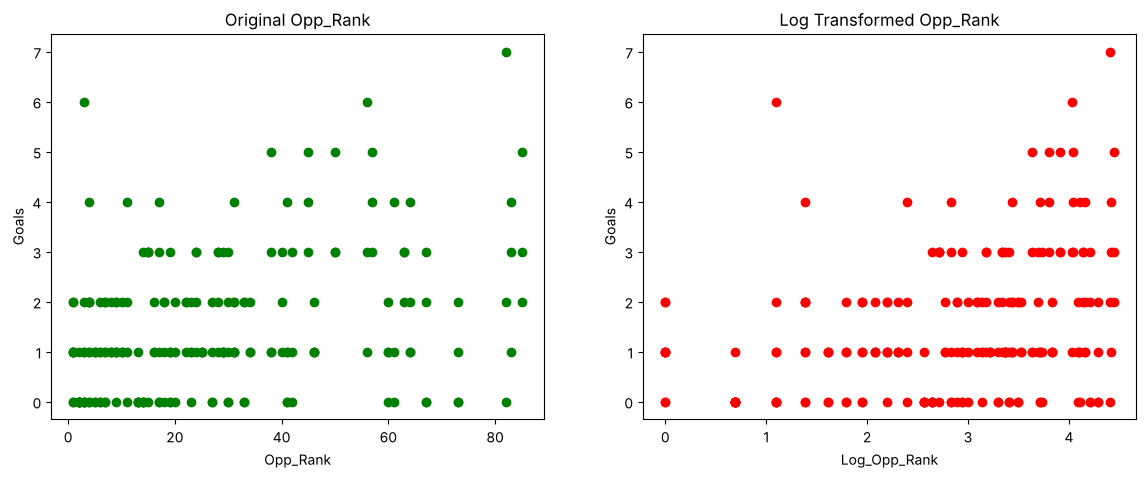

Correlation of Team_Rank with Goals: -0.367
Correlation of Log_Team_Rank with Goals: -0.369
Correlation of Opp_Rank with Goals: 0.345
Correlation of Log_Opp_Rank with Goals: 0.319


In [18]:
# Applying the log transformation to both ranking variables
df_log = df.copy()
df_log["Log_Team_Rank"] = np.log(df_log["Team_Rank"])
df_log["Log_Opp_Rank"] = np.log(df_log["Opp_Rank"])

# Visualise the effect of the transformation on the opponent's ranking
plt.figure(figsize=(14,5))

plt.subplot(1,2,1)
plt.scatter(df_log["Opp_Rank"], df_log["Goals"], color="green")
plt.title("Original Opp_Rank")
plt.xlabel("Opp_Rank")
plt.ylabel("Goals")

plt.subplot(1,2,2)
plt.scatter(df_log["Log_Opp_Rank"], df_log["Goals"], color="red")
plt.title("Log Transformed Opp_Rank")
plt.xlabel("Log_Opp_Rank")
plt.ylabel("Goals")

plt.show()

for col in ["Team_Rank", "Log_Team_Rank", "Opp_Rank", "Log_Opp_Rank"]:
    print("Correlation of %s with Goals: %.3f" % (col, df_log[col].corr(df_log["Goals"])))

In [19]:
# Drop the original ranking variables
df_log = df_log.drop(["Team_Rank", "Opp_Rank"], axis=1)

# Rearrange the variables so that Goals is the last column
df_log = df_log[["Log_Team_Rank", "Log_Opp_Rank", "Team_GoalsFor_Pre", "Opp_GoalsAgainst_Pre",
                 "Team_WC_Apps", "Host", "Knockout", "Team_Tourn_GoalsFor", "Goals"]]

x_log = df_log.iloc[:,:-1]
ols_log = evaluate_model(x_log, y_all, "Tip 1: log transformation of the rankings")

Tip 1: log transformation of the rankings
	 MAE: 1.072  RMSE: 1.405  NRMSE: 0.201  R^2: 0.061
	 Adjusted R^2 (statsmodels): 0.258


# Optimisation tip 2: Removing collinearity

We are checking for pairs of explanatory variables that are strongly correlated (|r| of 0.7 or more).

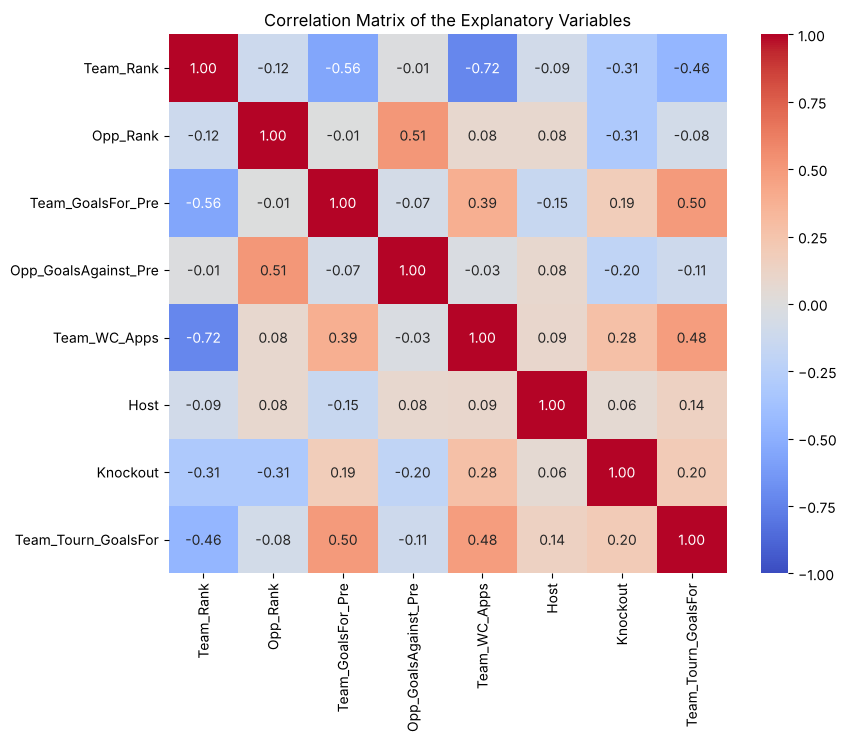

Strongly correlated pairs:
	 Team_Rank and Team_WC_Apps: r = -0.719


In [20]:
# Correlation matrix of the explanatory variables
corr = df.iloc[:,:-1].corr()

# Plotting the correlation matrix as a heatmap
plt.figure(figsize=(9,7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix of the Explanatory Variables")
plt.savefig("figures/2_2_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

# Printing the pairs with |r| >= 0.7
print("Strongly correlated pairs:")
for i in range(len(corr.columns)):
    for j in range(i+1, len(corr.columns)):
        if abs(corr.iloc[i,j]) >= 0.7:
            print("\t %s and %s: r = %.3f" % (corr.columns[i], corr.columns[j], corr.iloc[i,j]))

In [21]:
# Team_Rank and Team_WC_Apps are the only strongly correlated pair
# we remove Team_Rank because it had the higher p-value in the statsmodels summary
x_collinear = df.drop(["Team_Rank", "Goals"], axis=1)
ols_collinear = evaluate_model(x_collinear, y_all, "Tip 2: Team_Rank removed")

Tip 2: Team_Rank removed
	 MAE: 1.030  RMSE: 1.358  NRMSE: 0.194  R^2: 0.124
	 Adjusted R^2 (statsmodels): 0.261


# Optimisation tip 3: Rescaling with z-score standardisation

After standardisation all variables are on the same scale, so the coefficients can be compared to see which variables matter most.

Tip 3: z-score standardisation
	 MAE: 1.050  RMSE: 1.361  NRMSE: 0.194  R^2: 0.119
	 Adjusted R^2 (statsmodels): 0.260

Standardised coefficients:
Opp_GoalsAgainst_Pre    0.037
Knockout               -0.060
Team_Rank              -0.116
Host                    0.162
Team_Tourn_GoalsFor    -0.184
Team_WC_Apps            0.305
Opp_Rank                0.379
Team_GoalsFor_Pre       0.390
dtype: float64


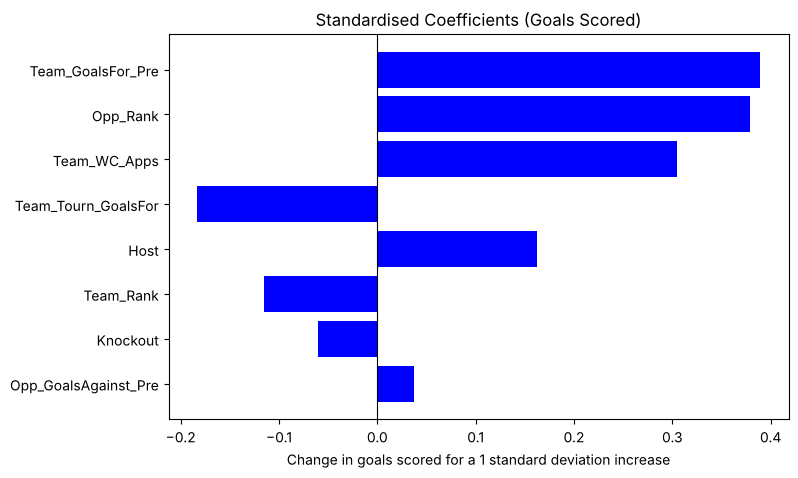

In [22]:
# Apply z-score standardisation to all explanatory variables
scaler = StandardScaler()
std_x = scaler.fit_transform(x_original.values)

# Restore the column names
std_x_df = pd.DataFrame(std_x, index=x_original.index, columns=x_original.columns)

ols_std = evaluate_model(std_x_df, y_all, "Tip 3: z-score standardisation")

# Standardised coefficients sorted by size
std_coef = ols_std.params.drop("const")
std_coef = std_coef.reindex(std_coef.abs().sort_values().index)
print("\nStandardised coefficients:")
print(std_coef.round(3))

# Plotting the standardised coefficients
plt.figure(figsize=(8,5))
plt.barh(std_coef.index, std_coef.values, color="blue")
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Change in goals scored for a 1 standard deviation increase")
plt.title("Standardised Coefficients (Goals Scored)")
plt.savefig("figures/2_2_standardised_coefficients.png", dpi=150, bbox_inches="tight")
plt.show()

# Optimisation tip 4: Gaussian transformation (Yeo-Johnson)

In [23]:
# Create a Yeo-Johnson transformer
transformer = PowerTransformer()

# Apply the transformer to make all explanatory variables more Gaussian-looking
gauss_x = transformer.fit_transform(x_original.values)

# Restore the column names
gauss_x_df = pd.DataFrame(gauss_x, index=x_original.index, columns=x_original.columns)

ols_gauss = evaluate_model(gauss_x_df, y_all, "Tip 4: Yeo-Johnson transformation")

Tip 4: Yeo-Johnson transformation
	 MAE: 1.087  RMSE: 1.404  NRMSE: 0.201  R^2: 0.063
	 Adjusted R^2 (statsmodels): 0.258


# Comparing all versions of the model

In [24]:
df_results = pd.DataFrame(results)
df_results.round(3)

,Model,Variables,MAE,RMSE,NRMSE,R^2 (test),R^2 (statsmodels),Adj. R^2 (statsmodels)
0,Original model,8,1.050,1.361,0.194,0.119,0.288,0.260
1,Tip 1: log transformation of the rankings,8,1.072,1.405,0.201,0.061,0.286,0.258
2,Tip 2: Team_Rank removed,7,1.030,1.358,0.194,0.124,0.286,0.261
3,Tip 3: z-score standardisation,8,1.050,1.361,0.194,0.119,0.288,0.260
4,Tip 4: Yeo-Johnson transformation,8,1.087,1.404,0.201,0.063,0.287,0.258


# Final model

Only Tip 2 improved the model, so the final model has Team_Rank removed. The dataset has 8 explanatory variables, but the final model uses 7.

In [25]:
# Final model: Team_Rank removed
x_final = df.drop(["Team_Rank", "Goals"], axis=1)
print("Variables in the final model:", list(x_final.columns))

ols_final = evaluate_model(x_final, y_all, "Final model (Tip 2)")

Variables in the final model: ['Opp_Rank', 'Team_GoalsFor_Pre', 'Opp_GoalsAgainst_Pre', 'Team_WC_Apps', 'Host', 'Knockout', 'Team_Tourn_GoalsFor']
Final model (Tip 2)
	 MAE: 1.030  RMSE: 1.358  NRMSE: 0.194  R^2: 0.124
	 Adjusted R^2 (statsmodels): 0.261


Goals = -1.2494 + 0.0168 (Opp_Rank) + 1.3156 (Team_GoalsFor_Pre) - 0.2623 (Opp_GoalsAgainst_Pre) + 0.0531 (Team_WC_Apps) + 0.6669 (Host) - 0.3562 (Knockout) - 0.1674 (Team_Tourn_GoalsFor)


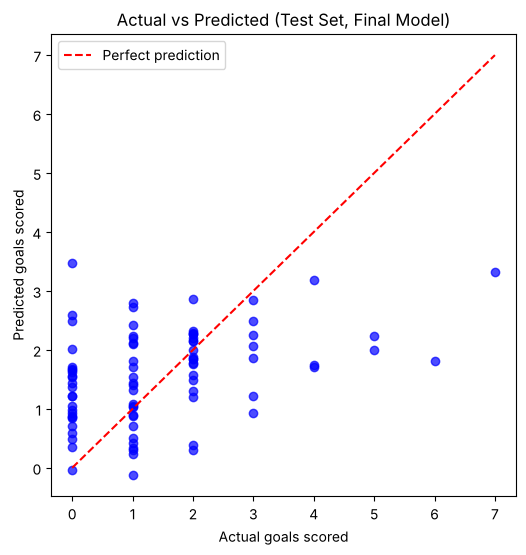

In [26]:
# Training the final model with sklearn to get the regression equation
X_train, X_test, y_train, y_test = train_test_split(x_final.values, y_all.values, test_size=0.4, random_state=0)
final_model = LinearRegression()
final_model.fit(X_train, y_train)
y_pred_final = final_model.predict(X_test)

equation = "Goals = %.4f" % final_model.intercept_
for name, coef in zip(x_final.columns, final_model.coef_):
    if coef >= 0:
        equation = equation + " + %.4f (%s)" % (coef, name)
    else:
        equation = equation + " - %.4f (%s)" % (abs(coef), name)
print(equation)

# Plotting the actual values against the predicted values
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred_final, color="blue", alpha=0.7)
plt.plot([0, 7], [0, 7], color="red", linestyle="--", label="Perfect prediction")
plt.xlabel("Actual goals scored")
plt.ylabel("Predicted goals scored")
plt.title("Actual vs Predicted (Test Set, Final Model)")
plt.legend()
plt.savefig("figures/2_2_actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

In [27]:
# statsmodels summary of the final model
print(ols_final.summary())

                            OLS Regression Results                            
Dep. Variable:                  Goals   R-squared:                       0.286
Model:                            OLS   Adj. R-squared:                  0.261
Method:                 Least Squares   F-statistic:                     11.43
Date:                Sat, 10 Oct 2026   Prob (F-statistic):           3.59e-12
Time:                        16:06:57   Log-Likelihood:                -328.66
No. Observations:                 208   AIC:                             673.3
Df Residuals:                     200   BIC:                             700.0
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   -1.1008 

# Repeated random splits

The test set only has 84 rows, so the results can change a lot depending on which rows are in it. We are repeating the 60/40 split 100 times and taking the average.

In [28]:
def repeated_split(x_df, y, repeats=100):
    r2_model = []
    rmse_model = []
    r2_base = []
    rmse_base = []
    for i in range(repeats):
        # a different split each time
        X_train, X_test, y_train, y_test = train_test_split(x_df.values, y.values, test_size=0.4, random_state=i)

        # linear regression model
        model = LinearRegression()
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        r2_model.append(metrics.r2_score(y_test, y_pred))
        rmse_model.append(math.sqrt(metrics.mean_squared_error(y_test, y_pred)))

        # baseline model
        y_pred_base = [np.mean(y_train)] * len(y_test)
        r2_base.append(metrics.r2_score(y_test, y_pred_base))
        rmse_base.append(math.sqrt(metrics.mean_squared_error(y_test, y_pred_base)))
    return np.mean(r2_model), np.mean(rmse_model), np.mean(r2_base), np.mean(rmse_base)

r2_o, rmse_o, r2_b, rmse_b = repeated_split(x_original, y_all)
r2_f, rmse_f, r2_b, rmse_b = repeated_split(x_final, y_all)

print("Average over 100 random 60/40 splits:")
print("\t Original model -> R^2: %.3f  RMSE: %.3f" % (r2_o, rmse_o))
print("\t Final model    -> R^2: %.3f  RMSE: %.3f" % (r2_f, rmse_f))
print("\t Baseline       -> R^2: %.3f  RMSE: %.3f" % (r2_b, rmse_b))

Average over 100 random 60/40 splits:
	 Original model -> R^2: 0.173  RMSE: 1.243
	 Final model    -> R^2: 0.177  RMSE: 1.240
	 Baseline       -> R^2: -0.023  RMSE: 1.386
